# SBA Loan Default: California Case Study
**Workflow**
1. Preprocessing and EDA(exploratory data analysis) 
2. WoE / IV feature transformation and selection
3. WoE + Logistic Regression and WoE + XGBoost estimation
4. Model evaluation: confusion matrix, AUC, Gini, KS, Brier score and log loss
5. Validation: overfitting, dummy baseline, stratified and temporal cross-validation, calibration, PSI and borrower-segment stability
6. Scenario-based assessment of the two example loan applications

The five original explanatory variables are retained, with additional WoE-transformed candidate variables. 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (6, 4)
SEED = 42
CUTOFF = 0.50

## 1. Preprocessing

In [2]:
import os
path = "SBAcase.csv" if os.path.exists("SBAcase.csv") else "data/SBAcase.csv"
df = pd.read_csv(path)
print(df.shape)
df.head()

(2102, 35)


,Selected,LoanNr_ChkDgt,Name,City,State,Zip,Bank,BankState,NAICS,ApprovalDate,...,ChgOffPrinGr,GrAppv,SBA_Appv,New,RealEstate,Portion,Recession,daysterm,xx,Default
0,0,1004285007,SIMPLEX OFFICE SOLUTIONS,ANAHEIM,CA,92801,CALIFORNIA BANK TRUST,CA,532420,15074,...,0,30000,15000,0,0,0.5,0,1080,16175.0,0
1,1,1004535010,DREAM HOME REALTY,TORRANCE,CA,90505,CALIFORNIA BANK TRUST,CA,531210,15130,...,0,30000,15000,0,0,0.5,1,1680,17658.0,0
2,0,1005005006,"Winset, Inc. dba Bankers Hill",SAN DIEGO,CA,92103,CALIFORNIA BANK TRUST,CA,531210,15188,...,0,30000,15000,0,0,0.5,0,1080,16298.0,0
3,1,1005535001,Shiva Management,SAN DIEGO,CA,92108,CALIFORNIA BANK TRUST,CA,531312,15719,...,0,50000,25000,0,0,0.5,0,1080,16816.0,0
4,1,1005996006,"GOLD CROWN HOME LOANS, INC",LOS ANGELES,CA,91345,SBA - EDF ENFORCEMENT ACTION,CO,531390,16840,...,0,343000,343000,0,1,1.0,0,7200,24103.0,0


### 1.1 Look at the data

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2102 entries, 0 to 2101
Data columns (total 35 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Selected           2102 non-null   int64  
 1   LoanNr_ChkDgt      2102 non-null   int64  
 2   Name               2102 non-null   object 
 3   City               2102 non-null   object 
 4   State              2102 non-null   object 
 5   Zip                2102 non-null   int64  
 6   Bank               2099 non-null   object 
 7   BankState          2099 non-null   object 
 8   NAICS              2102 non-null   int64  
 9   ApprovalDate       2102 non-null   int64  
 10  ApprovalFY         2102 non-null   int64  
 11  Term               2102 non-null   int64  
 12  NoEmp              2102 non-null   int64  
 13  NewExist           2101 non-null   float64
 14  CreateJob          2102 non-null   int64  
 15  RetainedJob        2102 non-null   int64  
 16  FranchiseCode      2102 

In [4]:
# Missing values (only columns that have some)
missing = df.isna().sum()
missing[missing > 0].sort_values(ascending=False)

ChgOffDate          1405
Bank                   3
BankState              3
LowDoc                 3
DisbursementDate       3
xx                     3
RevLineCr              2
NewExist               1
dtype: int64

### 1.2 Cleaning

- remove duplicated loans
- `MIS_Status` has spaces in `P I F`, so I clean it and rebuild the target **Default** (1 = charged off, 0 = paid in full)
- the dates are SAS dates (days since 1960-01-01), I convert them to real dates

In [5]:
df = df.drop_duplicates(subset="LoanNr_ChkDgt").copy()

# Target
df["MIS_Status"] = df["MIS_Status"].astype(str).str.replace(" ", "")   # "P I F" -> "PIF"
df = df[df["MIS_Status"].isin(["CHGOFF", "PIF"])]
df["Default"] = (df["MIS_Status"] == "CHGOFF").astype(int)

# Dates (SAS dates -> real dates)
for c in ["ApprovalDate", "DisbursementDate", "ChgOffDate"]:
    df[c] = pd.to_datetime(df[c], unit="D", origin="1960-01-01", errors="coerce")

print(df.shape)
df["Default"].value_counts()

(2102, 35)


Default
0    1416
1     686
Name: count, dtype: int64

### 1.3 Prepare the variables

The dataset already contains the variables created by the authors (journal of statistics education): `New`, `RealEstate`, `Portion`, `Recession`.
iam gonna check if they match their definitions:

In [6]:
print("RealEstate matches Term >= 240 :", (df["RealEstate"] == (df["Term"] >= 240).astype(int)).mean().round(4))
print("New matches NewExist == 2      :", (df["New"] == (df["NewExist"] == 2).astype(int)).mean().round(4))
print("Portion matches SBA_Appv/GrAppv:", np.isclose(df["Portion"], df["SBA_Appv"] / df["GrAppv"]).mean().round(4))

RealEstate matches Term >= 240 : 1.0
New matches NewExist == 2      : 1.0
Portion matches SBA_Appv/GrAppv: 1.0


In [7]:
# Five explanatory variables used in the California case study
FEATURES_5 = ["Recession", "New", "RealEstate", "DisbursementGross", "Portion"]
TARGET = "Default"

# Keep rows with complete values for the five original predictors and target.
df = df.dropna(subset=FEATURES_5 + [TARGET]).reset_index(drop=True)
print(df.shape)
df[FEATURES_5 + [TARGET]].describe().T

(2102, 35)


,count,mean,std,min,25%,50%,75%,max
Recession,2102.0,0.068506,0.252673,0.00000,0.0,0.0,0.00,1.0
New,2102.0,0.154139,0.361168,0.00000,0.0,0.0,0.00,1.0
RealEstate,2102.0,0.274500,0.446368,0.00000,0.0,0.0,1.00,1.0
DisbursementGross,2102.0,242737.212179,338286.101816,4835.00000,40000.0,100000.0,300000.00,2315000.0
Portion,2102.0,0.671055,0.186519,0.29677,0.5,0.5,0.85,1.0
Default,2102.0,0.326356,0.468991,0.00000,0.0,0.0,1.00,1.0


## 2. EDA

In [8]:
print("Number of loans      :", len(df))
print("Default rate         :", round(df["Default"].mean() * 100, 2), "%")
print("Paid in full         :", (df["Default"] == 0).sum())
print("Charged off          :", (df["Default"] == 1).sum())
print()
print("Default rate by RealEstate:")
print((df.groupby("RealEstate")["Default"].mean() * 100).round(2))
print()
print("Default rate by Recession:")
print((df.groupby("Recession")["Default"].mean() * 100).round(2))

Number of loans      : 2102
Default rate         : 32.64 %
Paid in full         : 1416
Charged off          : 686

Default rate by RealEstate:
RealEstate
0    43.28
1     4.51
Name: Default, dtype: float64

Default rate by Recession:
Recession
0    31.00
1    54.86
Name: Default, dtype: float64


### Graph 1: distribution of the loan amount

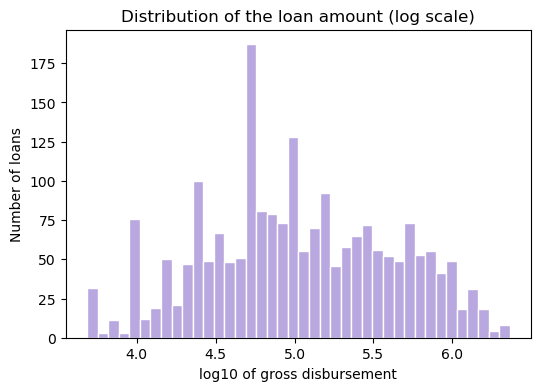

In [35]:

plt.hist(np.log10(df["DisbursementGross"]), bins=40, color="#b9a7e0", edgecolor="white")
plt.xlabel("log10 of gross disbursement")
plt.ylabel("Number of loans")
plt.title("Distribution of the loan amount (log scale)")
plt.show()

### Graph 2: default rate with and without real estate

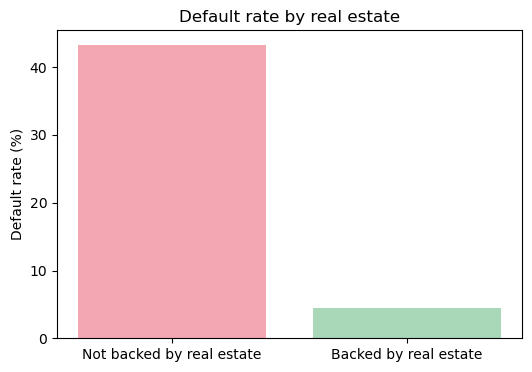

In [10]:
rate = df.groupby("RealEstate")["Default"].mean() * 100
plt.bar(["Not backed by real estate", "Backed by real estate"], rate.values, color=["#f2a7b3", "#a9d8b8"])
plt.ylabel("Default rate (%)")
plt.title("Default rate by real estate")
plt.show()

### Graph 3: default rate during and outside the recession

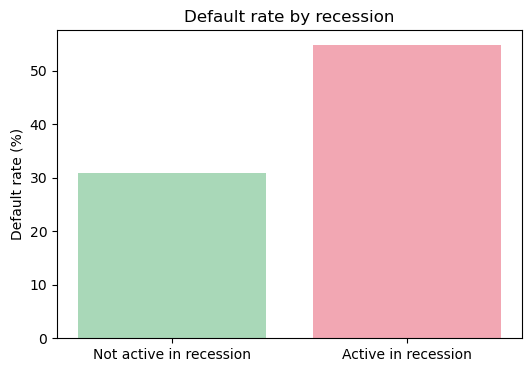

In [11]:
rate = df.groupby("Recession")["Default"].mean() * 100
plt.bar(["Not active in recession", "Active in recession"], rate.values, color=["#a9d8b8", "#f2a7b3"])
plt.ylabel("Default rate (%)")
plt.title("Default rate by recession")
plt.show()

### Graph 4: SBA guaranteed portion, paid in full vs. default

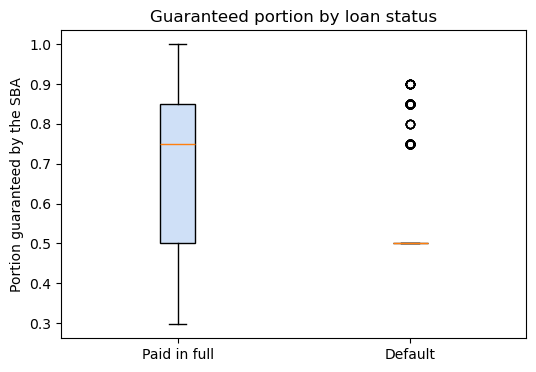

In [12]:
data_box = [df.loc[df["Default"] == 0, "Portion"], df.loc[df["Default"] == 1, "Portion"]]
plt.boxplot(data_box, patch_artist=True, boxprops=dict(facecolor="#cfe0f7"))
plt.xticks([1, 2], ["Paid in full", "Default"])
plt.ylabel("Portion guaranteed by the SBA")
plt.title("Guaranteed portion by loan status")
plt.show()

## 3. WoE-based model estimation

The estimation stage keeps the **five explanatory variables** used in the California case study (`Recession`, `New`, `RealEstate`, `DisbursementGross`, and `Portion`) and adds WoE-transformed information from other available borrower/loan variables.

Only two models are estimated:
- **WoE + Logistic Regression**
- **WoE + XGBoost**

WoE bins, IV-based feature selection, and scaling are fitted within each training fold or training split to prevent leakage. MinMax scaling is used only for Logistic Regression; XGBoost does not require feature scaling.

In [13]:
# Required imports for estimation and validation
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, StratifiedKFold, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, roc_curve, confusion_matrix, classification_report,
    brier_score_loss, log_loss, precision_score, recall_score, f1_score
)
from sklearn.dummy import DummyClassifier
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier

SEED = 42
CUTOFF = 0.50
IV_THRESHOLD = 0.02
GAP_LIMIT = 0.05

### 3.1 Keep five original variables and prepare additional WoE candidates

The five original variables remain in the model as raw explanatory variables. Additional available variables are transformed into WoE features. The candidate list is restricted to information available at or before loan origination; post-default variables must never be included.

In [14]:
FEATURES_5 = ["Recession", "New", "RealEstate", "DisbursementGross", "Portion"]
TARGET = "Default"

def add_features(data):
    data = data.copy()

    # Simple, interpretable features available at or around loan origination.
    if "FranchiseCode" in data.columns:
        franchise = pd.to_numeric(data["FranchiseCode"], errors="coerce")
        data["IsFranchise"] = (franchise.fillna(0) > 1).astype(int)

    if "NAICS" in data.columns:
        naics = pd.to_numeric(data["NAICS"], errors="coerce")
        data["NAICS4"] = (naics // 100).astype("Int64").astype("string")
        data.loc[data["NAICS4"].isin(["<NA>", "nan"]), "NAICS4"] = pd.NA

    if "NoEmp" in data.columns and "DisbursementGross" in data.columns:
        employees = pd.to_numeric(data["NoEmp"], errors="coerce").clip(lower=1)
        amount = pd.to_numeric(data["DisbursementGross"], errors="coerce")
        data["LoanPerEmployee"] = amount / employees

    for col in ["LowDoc", "RevLineCr", "UrbanRural"]:
        if col in data.columns:
            data[col] = data[col].astype("string")

    return data

df = add_features(df)

# Only use candidate variables that are available at or before loan origination.
# Explicitly exclude charge-off, recovery, balance-after-default and other outcome-derived fields.
WOE_CANDIDATES_ALL = [
    "NoEmp", "NAICS4", "UrbanRural", "LowDoc", "RevLineCr", "IsFranchise",
    "Term", "SBA_Appv", "GrAppv", "CreateJob", "RetainedJob",
    "ApprovalFY", "LoanPerEmployee"
]
POST_OUTCOME_OR_LEAKAGE_FIELDS = {
    "MIS_Status", "Default", "ChgOffDate", "ChgOffPrinGr",
    "BalanceGross", "Balance", "RecoveryAmount", "RecoveryDate",
    "GrossAmountBalance"
}
WOE_CANDIDATES = [
    c for c in WOE_CANDIDATES_ALL
    if c in df.columns and c not in FEATURES_5
    and c not in POST_OUTCOME_OR_LEAKAGE_FIELDS
]
MODEL_INPUTS = FEATURES_5 + WOE_CANDIDATES

missing_required = [c for c in FEATURES_5 + [TARGET] if c not in df.columns]
if missing_required:
    raise ValueError(f"Missing required columns: {missing_required}")

print("Five original variables:", FEATURES_5)
print("Additional WoE candidates:", WOE_CANDIDATES)
print("Total model inputs:", len(MODEL_INPUTS))
print("Excluded outcome/leakage fields:", sorted(POST_OUTCOME_OR_LEAKAGE_FIELDS.intersection(df.columns)))

Five original variables: ['Recession', 'New', 'RealEstate', 'DisbursementGross', 'Portion']
Additional WoE candidates: ['NoEmp', 'NAICS4', 'UrbanRural', 'LowDoc', 'RevLineCr', 'IsFranchise', 'Term', 'SBA_Appv', 'GrAppv', 'CreateJob', 'RetainedJob', 'ApprovalFY', 'LoanPerEmployee']
Total model inputs: 18
Excluded outcome/leakage fields: ['BalanceGross', 'ChgOffDate', 'ChgOffPrinGr', 'Default', 'MIS_Status']


### 3.2 Stratified 70/30 train-test split

The test set is held back for final evaluation. WoE binning, IV selection, and scaling are learned from training data only.

In [15]:
X = df[MODEL_INPUTS].copy()
y = df[TARGET].astype(int).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED
)
train_df = X_train.copy()

print(f"Training set: {X_train.shape[0]:,} loans | default rate: {y_train.mean():.3%}")
print(f"Testing set : {X_test.shape[0]:,} loans | default rate: {y_test.mean():.3%}")

Training set: 1,471 loans | default rate: 32.631%
Testing set : 631 loans | default rate: 32.647%


### 3.3 Custom WoE / IV transformer

WoE is defined here as `ln(distribution of defaults / distribution of non-defaults)`, so positive WoE indicates a riskier bin. Laplace smoothing avoids infinite values when a bin contains no defaults or no non-defaults. IV selection uses the training data only, with an IV threshold of 0.02. Variables with IV above 0.50 are flagged for a leakage review rather than automatically accepted.

In [16]:
class WoEIVTransformer(BaseEstimator, TransformerMixin):
    """Fit bins, WoE values and IV-based feature selection on the supplied training fold."""
    def __init__(self, n_bins=5, min_count=20, iv_threshold=0.02, smoothing=0.5):
        self.n_bins = n_bins
        self.min_count = min_count
        self.iv_threshold = iv_threshold
        self.smoothing = smoothing

    def _make_bins(self, series, col, fitting=False):
        s = pd.Series(series).copy()
        if col in self.numeric_cols_:
            s = pd.to_numeric(s, errors="coerce").fillna(self.medians_[col])
            return pd.cut(s, bins=self.edges_[col], labels=False, include_lowest=True).astype("Int64").astype(str)
        s = s.astype("string").fillna("__MISSING__")
        return s.where(s.isin(self.kept_categories_[col]), "__OTHER__").astype(str)

    def fit(self, X, y):
        X = pd.DataFrame(X).copy()
        y = pd.Series(np.asarray(y).astype(int)).reset_index(drop=True)
        X = X.reset_index(drop=True)

        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.numeric_cols_ = []
        self.edges_, self.medians_, self.kept_categories_ = {}, {}, {}
        self.woe_maps_, self.iv_ = {}, {}

        for col in X.columns:
            s_num = pd.to_numeric(X[col], errors="coerce")
            is_numeric = pd.api.types.is_numeric_dtype(X[col]) and s_num.nunique(dropna=True) > self.n_bins

            if is_numeric:
                self.numeric_cols_.append(col)
                self.medians_[col] = float(s_num.median()) if s_num.notna().any() else 0.0
                filled = s_num.fillna(self.medians_[col])
                quantiles = np.unique(np.quantile(filled, np.linspace(0, 1, self.n_bins + 1)))
                if len(quantiles) < 3:
                    quantiles = np.array([-np.inf, np.inf])
                else:
                    quantiles[0], quantiles[-1] = -np.inf, np.inf
                self.edges_[col] = quantiles
            else:
                values = X[col].astype("string").fillna("__MISSING__")
                counts = values.value_counts()
                self.kept_categories_[col] = set(counts[counts >= self.min_count].index.astype(str))

            bins = self._make_bins(X[col], col)
            table = pd.crosstab(bins, y).reindex(columns=[0, 1], fill_value=0).astype(float)
            table += self.smoothing
            dist_nondefault = table[0] / table[0].sum()
            dist_default = table[1] / table[1].sum()
            woe = np.log(dist_default / dist_nondefault)
            self.woe_maps_[col] = woe.to_dict()
            self.iv_[col] = float(((dist_default - dist_nondefault) * woe).sum())

        iv_series = pd.Series(self.iv_).sort_values(ascending=False)
        self.selected_features_ = iv_series[iv_series >= self.iv_threshold].index.tolist()
        if not self.selected_features_ and len(iv_series):
            self.selected_features_ = [iv_series.index[0]]
        self.iv_table_ = pd.DataFrame({"IV": iv_series})
        self.iv_table_["Interpretation"] = pd.cut(
            self.iv_table_["IV"],
            bins=[-np.inf, 0.02, 0.10, 0.30, 0.50, np.inf],
            labels=["Very weak", "Weak", "Medium", "Strong", "Investigate: IV > 0.50"],
            right=False
        )
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        output = {}
        for col in self.selected_features_:
            bins = self._make_bins(X[col], col)
            output[col + "_woe"] = bins.map(self.woe_maps_[col]).fillna(0.0).astype(float).to_numpy()
        return pd.DataFrame(output, index=X.index)

    def get_feature_names_out(self, input_features=None):
        return np.asarray([c + "_woe" for c in self.selected_features_], dtype=object)

### 3.4 Build and tune the two WoE models

The same five original variables and the additional WoE candidate set are supplied to both models. WoE binning and IV selection are re-fitted inside every cross-validation fold. Logistic Regression uses MinMax scaling; XGBoost does not require feature scaling.

To improve performance without contaminating the test set, use randomized hyperparameter search with stratified 5-fold CV on the **training partition only**. The search tunes WoE binning/IV settings as well as model regularization and complexity. The held-out 30% test set is reserved for the final, unbiased comparison.

In [17]:
from sklearn.model_selection import RandomizedSearchCV

# Base XGBoost settings. RandomizedSearchCV will tune the main complexity and
# regularization parameters using training data only.
XGB_PARAMS = dict(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=SEED,
    n_jobs=1
)

def make_woe_model(model_type):
    preprocessing = ColumnTransformer(
        transformers=[
            ("raw_five", "passthrough", FEATURES_5),
            ("woe", WoEIVTransformer(n_bins=5, min_count=20, iv_threshold=IV_THRESHOLD), WOE_CANDIDATES)
        ],
        remainder="drop",
        verbose_feature_names_out=False
    )

    if model_type == "logit":
        return make_pipeline(
            preprocessing,
            MinMaxScaler(),
            LogisticRegression(max_iter=3000, solver="lbfgs")
        )

    if model_type == "xgb":
        return make_pipeline(preprocessing, XGBClassifier(**XGB_PARAMS))

    raise ValueError("model_type must be 'logit' or 'xgb'")

MODEL_TYPES = {
    "WoE + Logistic Regression": "logit",
    "WoE + XGBoost": "xgb"
}

# Search spaces are deliberately bounded to reduce overfitting on this relatively
# small California/NAICS-53 sample. The 30% test set is not used for tuning.
negative_positive_ratio = (y_train == 0).sum() / max((y_train == 1).sum(), 1)

PARAM_DISTRIBUTIONS = {
    "logit": {
        "columntransformer__woe__n_bins": [3, 4, 5, 6, 8],
        "columntransformer__woe__iv_threshold": [0.01, 0.02, 0.03, 0.05],
        "columntransformer__woe__min_count": [10, 20, 30, 40],
        "logisticregression__C": [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0],
        "logisticregression__class_weight": [None, "balanced"]
    },
    "xgb": {
        "columntransformer__woe__n_bins": [3, 4, 5, 6, 8],
        "columntransformer__woe__iv_threshold": [0.01, 0.02, 0.03, 0.05],
        "columntransformer__woe__min_count": [10, 20, 30, 40],
        "xgbclassifier__n_estimators": [100, 200, 300, 450, 600],
        "xgbclassifier__max_depth": [1, 2, 3, 4],
        "xgbclassifier__learning_rate": [0.01, 0.02, 0.04, 0.06, 0.08],
        "xgbclassifier__subsample": [0.65, 0.8, 0.95, 1.0],
        "xgbclassifier__colsample_bytree": [0.6, 0.75, 0.9, 1.0],
        "xgbclassifier__min_child_weight": [1, 3, 5, 8, 12],
        "xgbclassifier__gamma": [0, 0.1, 0.3, 0.6, 1.0],
        "xgbclassifier__reg_alpha": [0, 0.01, 0.1, 0.5, 1.0],
        "xgbclassifier__reg_lambda": [1, 3, 5, 10, 20],
        "xgbclassifier__scale_pos_weight": [1.0, negative_positive_ratio]
    }
}

tuning_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
models = {}
searches = {}
tuning_rows = []

for name, model_type in MODEL_TYPES.items():
    print(f"Training and tuning: {name}")
    search = RandomizedSearchCV(
        estimator=make_woe_model(model_type),
        param_distributions=PARAM_DISTRIBUTIONS[model_type],
        n_iter=20 if model_type == "logit" else 35,
        scoring="roc_auc",
        cv=tuning_cv,
        refit=True,
        random_state=SEED,
        n_jobs=-1,
        verbose=1,
        return_train_score=True
    )
    search.fit(X_train, y_train)

    searches[name] = search
    models[name] = search.best_estimator_
    tuning_rows.append({
        "Model": name,
        "Best mean CV AUC": search.best_score_,
        "Best parameters": search.best_params_
    })
    print(f"Best training-CV AUC: {search.best_score_:.4f}")

tuning_summary = pd.DataFrame(tuning_rows).set_index("Model")
display(tuning_summary[["Best mean CV AUC"]].round(4))
for name, search in searches.items():
    print(f"\n{name} — selected hyperparameters")
    print(search.best_params_)

print("\nImportant: hyperparameter tuning used only the 70% training partition. "
      "The 30% test partition remains untouched until final evaluation.")

Training and tuning: WoE + Logistic Regression
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best training-CV AUC: 0.9342
Training and tuning: WoE + XGBoost
Fitting 5 folds for each of 35 candidates, totalling 175 fits
Best training-CV AUC: 0.9564


,Best mean CV AUC
Model,
WoE + Logistic Regression,0.9342
WoE + XGBoost,0.9564



WoE + Logistic Regression — selected hyperparameters
{'logisticregression__class_weight': None, 'logisticregression__C': 3.0, 'columntransformer__woe__n_bins': 6, 'columntransformer__woe__min_count': 20, 'columntransformer__woe__iv_threshold': 0.05}

WoE + XGBoost — selected hyperparameters
{'xgbclassifier__subsample': 1.0, 'xgbclassifier__scale_pos_weight': np.float64(2.064583333333333), 'xgbclassifier__reg_lambda': 5, 'xgbclassifier__reg_alpha': 1.0, 'xgbclassifier__n_estimators': 200, 'xgbclassifier__min_child_weight': 5, 'xgbclassifier__max_depth': 4, 'xgbclassifier__learning_rate': 0.02, 'xgbclassifier__gamma': 0.3, 'xgbclassifier__colsample_bytree': 0.75, 'columntransformer__woe__n_bins': 6, 'columntransformer__woe__min_count': 40, 'columntransformer__woe__iv_threshold': 0.02}

Important: hyperparameter tuning used only the 70% training partition. The 30% test partition remains untouched until final evaluation.


## 4. Model evaluation

Evaluate both models on the untouched 30% test set. AUC measures ranking, while the confusion matrix and classification metrics measure decisions at the chosen cutoff. Brier score and log loss assess the quality of the estimated probabilities.

In [18]:
def ks_statistic(y_true, probabilities):
    fpr, tpr, _ = roc_curve(y_true, probabilities)
    return float(np.max(tpr - fpr))

def evaluate_model(y_true, probabilities, cutoff=CUTOFF):
    y_true = np.asarray(y_true).astype(int)
    probabilities = np.clip(np.asarray(probabilities, dtype=float), 1e-8, 1 - 1e-8)
    predictions = (probabilities >= cutoff).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    auc = roc_auc_score(y_true, probabilities)
    return {
        "Accuracy": (tp + tn) / (tp + tn + fp + fn),
        "Precision (default)": precision_score(y_true, predictions, zero_division=0),
        "Recall (default)": recall_score(y_true, predictions, zero_division=0),
        "F1 (default)": f1_score(y_true, predictions, zero_division=0),
        "Specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "ROC-AUC": auc,
        "Gini": 2 * auc - 1,
        "KS": ks_statistic(y_true, probabilities),
        "Brier score": brier_score_loss(y_true, probabilities),
        "Log loss": log_loss(y_true, probabilities, labels=[0, 1]),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    }

test_proba = {name: model.predict_proba(X_test)[:, 1] for name, model in models.items()}
train_proba = {name: model.predict_proba(X_train)[:, 1] for name, model in models.items()}
test_results = {name: evaluate_model(y_test, p) for name, p in test_proba.items()}
results_df = pd.DataFrame(test_results).T
display(results_df.round(4))

,Accuracy,Precision (default),Recall (default),F1 (default),Specificity,ROC-AUC,Gini,KS,Brier score,Log loss,TN,FP,FN,TP
WoE + Logistic Regression,0.8922,0.8520,0.8107,0.8308,0.9318,0.9309,0.8617,0.7547,0.0906,0.3054,396.0,29.0,39.0,167.0
WoE + XGBoost,0.8970,0.8279,0.8641,0.8456,0.9129,0.9502,0.9005,0.7875,0.0835,0.2871,388.0,37.0,28.0,178.0


### 4.1 Confusion matrices and classification reports

In [19]:
for name, probabilities in test_proba.items():
    predictions = (probabilities >= CUTOFF).astype(int)
    print(f"\n{name} — cutoff = {CUTOFF:.2f}")
    print(classification_report(y_test, predictions, labels=[0, 1],
                                target_names=["Paid in full", "Default"], zero_division=0))
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])
    display(pd.DataFrame(cm, index=["Actual paid", "Actual default"],
                         columns=["Predicted paid", "Predicted default"]))


WoE + Logistic Regression — cutoff = 0.50
              precision    recall  f1-score   support

Paid in full       0.91      0.93      0.92       425
     Default       0.85      0.81      0.83       206

    accuracy                           0.89       631
   macro avg       0.88      0.87      0.88       631
weighted avg       0.89      0.89      0.89       631



,Predicted paid,Predicted default
Actual paid,396,29
Actual default,39,167



WoE + XGBoost — cutoff = 0.50
              precision    recall  f1-score   support

Paid in full       0.93      0.91      0.92       425
     Default       0.83      0.86      0.85       206

    accuracy                           0.90       631
   macro avg       0.88      0.89      0.88       631
weighted avg       0.90      0.90      0.90       631



,Predicted paid,Predicted default
Actual paid,388,37
Actual default,28,178


### 4.2 ROC curves

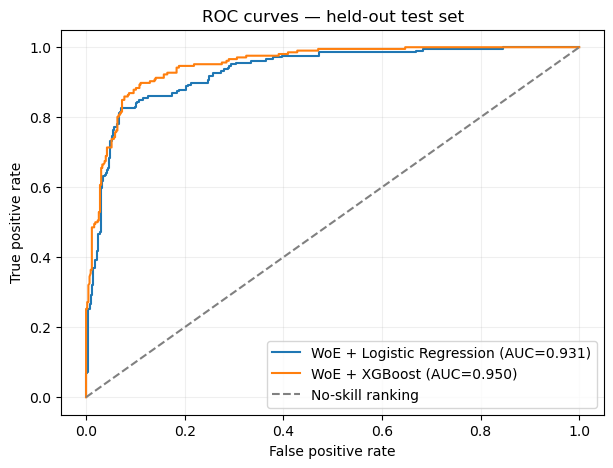

In [20]:
plt.figure(figsize=(7, 5))
for name, probabilities in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, probabilities):.3f})")
plt.plot([0, 1], [0, 1], "--", color="grey", label="No-skill ranking")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves — held-out test set")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 5. Model validation

The validation procedures below use the training data for model development and keep the 30% test set separate. All pipelines re-fit WoE binning, IV selection and scaling inside each fold.

### 5.1 Overfitting check: training AUC versus testing AUC

A train-test AUC gap greater than 0.05 is flagged for investigation. A negative gap is also shown rather than treated as overfitting.

In [21]:
overfit_rows = []
for name in models:
    auc_train = roc_auc_score(y_train, train_proba[name])
    auc_test = roc_auc_score(y_test, test_proba[name])
    gap = auc_train - auc_test
    overfit_rows.append({
        "Model": name, "Train AUC": auc_train, "Test AUC": auc_test,
        "Train - test gap": gap,
        "Flag": "CHECK OVERFITTING" if gap > GAP_LIMIT else "No gap flag"
    })
overfit_df = pd.DataFrame(overfit_rows).set_index("Model")
display(overfit_df.round(4))

,Train AUC,Test AUC,Train - test gap,Flag
Model,,,,
WoE + Logistic Regression,0.9440,0.9309,0.0132,No gap flag
WoE + XGBoost,0.9698,0.9502,0.0195,No gap flag


### 5.2 DummyClassifier baseline

The majority-class baseline always predicts the most frequent class. Its probabilities and classification results provide a simple reference; it is not expected to discriminate between good and bad loans.

In [22]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_probabilities = dummy.predict_proba(X_test)[:, 1]
baseline_results = {"Dummy — majority class": evaluate_model(y_test, dummy_probabilities)}
baseline_results.update(test_results)
baseline_df = pd.DataFrame(baseline_results).T
display(baseline_df.round(4))

,Accuracy,Precision (default),Recall (default),F1 (default),Specificity,ROC-AUC,Gini,KS,Brier score,Log loss,TN,FP,FN,TP
Dummy — majority class,0.6735,0.0000,0.0000,0.0000,1.0000,0.5000,0.0000,0.0000,0.3265,6.0137,425.0,0.0,206.0,0.0
WoE + Logistic Regression,0.8922,0.8520,0.8107,0.8308,0.9318,0.9309,0.8617,0.7547,0.0906,0.3054,396.0,29.0,39.0,167.0
WoE + XGBoost,0.8970,0.8279,0.8641,0.8456,0.9129,0.9502,0.9005,0.7875,0.0835,0.2871,388.0,37.0,28.0,178.0


### 5.3 Stratified 5-fold cross-validation

Cross-validation is run on the training set only. WoE and IV selection are re-estimated inside every fold. Report mean and standard deviation of AUC, along with fold-level variation. Since hyperparameters were selected using training-set CV, treat this section primarily as a fold-stability diagnostic; the untouched 30% test result remains the final holdout estimate.

In [23]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
stratified_fold_results = {}

for name, model in models.items():
    fold_rows = []
    for fold, (train_idx, valid_idx) in enumerate(skf.split(X_train, y_train), start=1):
        fold_model = clone(model)
        X_fold_train, X_fold_valid = X_train.iloc[train_idx], X_train.iloc[valid_idx]
        y_fold_train, y_fold_valid = y_train.iloc[train_idx], y_train.iloc[valid_idx]
        fold_model.fit(X_fold_train, y_fold_train)
        p_train = fold_model.predict_proba(X_fold_train)[:, 1]
        p_valid = fold_model.predict_proba(X_fold_valid)[:, 1]
        fold_rows.append({
            "Fold": fold,
            "Train AUC": roc_auc_score(y_fold_train, p_train),
            "Validation AUC": roc_auc_score(y_fold_valid, p_valid),
            "Validation KS": ks_statistic(y_fold_valid, p_valid),
            "Validation Brier": brier_score_loss(y_fold_valid, p_valid)
        })
    stratified_fold_results[name] = pd.DataFrame(fold_rows).set_index("Fold")

cv_summary_rows = []
for name, fold_df in stratified_fold_results.items():
    aucs = fold_df["Validation AUC"]
    cv_summary_rows.append({
        "Model": name,
        "Mean AUC": aucs.mean(),
        "Std AUC": aucs.std(ddof=1),
        "Min AUC": aucs.min(),
        "Max AUC": aucs.max(),
        "AUC range": aucs.max() - aucs.min()
    })
cv_summary = pd.DataFrame(cv_summary_rows).set_index("Model")
display(cv_summary.round(4))

for name, fold_df in stratified_fold_results.items():
    print(name)
    display(fold_df.round(4))

,Mean AUC,Std AUC,Min AUC,Max AUC,AUC range
Model,,,,,
WoE + Logistic Regression,0.9342,0.0118,0.9170,0.9426,0.0256
WoE + XGBoost,0.9564,0.0066,0.9461,0.9640,0.0179


WoE + Logistic Regression


,Train AUC,Validation AUC,Validation KS,Validation Brier
Fold,,,,
1,0.9401,0.9426,0.7644,0.0819
2,0.9443,0.9426,0.8103,0.0763
3,0.9554,0.9170,0.7440,0.1012
4,0.9405,0.9267,0.7462,0.0902
5,0.9435,0.9420,0.7686,0.0870


WoE + XGBoost


,Train AUC,Validation AUC,Validation KS,Validation Brier
Fold,,,,
1,0.9689,0.9566,0.7910,0.0815
2,0.9713,0.9640,0.8261,0.0741
3,0.9738,0.9461,0.7563,0.0987
4,0.9658,0.9559,0.7519,0.0872
5,0.9682,0.9594,0.8475,0.0823


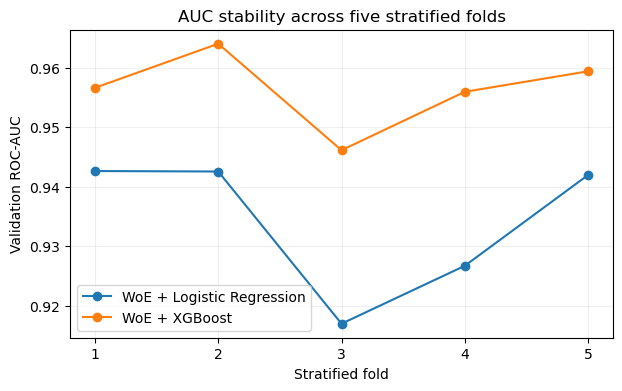

In [24]:
plt.figure(figsize=(7, 4))
for name, fold_df in stratified_fold_results.items():
    plt.plot(fold_df.index, fold_df["Validation AUC"], marker="o", label=name)
plt.xlabel("Stratified fold")
plt.ylabel("Validation ROC-AUC")
plt.title("AUC stability across five stratified folds")
plt.xticks(range(1, 6))
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### 5.4 Expanding-window and rolling-window temporal cross-validation

Loans are ordered by disbursement date. Expanding-window validation trains on the oldest available training observations and tests on the next period, with the training window growing over time. Rolling-window validation uses a fixed-size training window. These checks are restricted to the training partition; the held-out test set remains untouched.

In [25]:
def temporal_cv_scores(model, X_part, y_part, dates, mode="expanding", n_splits=5):
    order = pd.to_datetime(dates, errors="coerce").sort_values().index
    X_ordered = X_part.loc[order]
    y_ordered = y_part.loc[order]
    n = len(X_ordered)
    max_train = max(2, int(n * 0.50)) if mode == "rolling" else None
    splitter = TimeSeriesSplit(n_splits=n_splits, max_train_size=max_train)
    rows = []

    for fold, (tr_idx, va_idx) in enumerate(splitter.split(X_ordered), start=1):
        y_tr, y_va = y_ordered.iloc[tr_idx], y_ordered.iloc[va_idx]
        if y_tr.nunique() < 2 or y_va.nunique() < 2:
            continue
        fold_model = clone(model)
        fold_model.fit(X_ordered.iloc[tr_idx], y_tr)
        p_va = fold_model.predict_proba(X_ordered.iloc[va_idx])[:, 1]
        rows.append({
            "Fold": fold,
            "Train start": dates.loc[order].iloc[tr_idx].min(),
            "Train end": dates.loc[order].iloc[tr_idx].max(),
            "Validation start": dates.loc[order].iloc[va_idx].min(),
            "Validation end": dates.loc[order].iloc[va_idx].max(),
            "Validation AUC": roc_auc_score(y_va, p_va),
            "Validation KS": ks_statistic(y_va, p_va)
        })
    return pd.DataFrame(rows)

if "DisbursementDate" not in df.columns:
    print("Temporal CV skipped: DisbursementDate is not available.")
else:
    train_dates = pd.to_datetime(df.loc[X_train.index, "DisbursementDate"], errors="coerce")
    valid_date_mask = train_dates.notna()
    X_temporal = X_train.loc[valid_date_mask]
    y_temporal = y_train.loc[valid_date_mask]
    dates_temporal = train_dates.loc[valid_date_mask]

    temporal_results = {}
    for name, model in models.items():
        temporal_results[name] = {
            "Expanding": temporal_cv_scores(model, X_temporal, y_temporal, dates_temporal, "expanding"),
            "Rolling": temporal_cv_scores(model, X_temporal, y_temporal, dates_temporal, "rolling")
        }
        print(f"\n{name} — expanding window")
        display(temporal_results[name]["Expanding"].round(4))
        print(f"{name} — rolling window")
        display(temporal_results[name]["Rolling"].round(4))


WoE + Logistic Regression — expanding window


,Fold,Train start,Train end,Validation start,Validation end,Validation AUC,Validation KS
0,1,1989-01-31,2001-12-31,2001-12-31,2004-03-31,0.7779,0.5523
1,2,1989-01-31,2004-03-31,2004-03-31,2005-09-30,0.8964,0.7680
2,3,1989-01-31,2005-09-30,2005-09-30,2006-09-30,0.8758,0.7079
3,4,1989-01-31,2006-09-30,2006-09-30,2007-07-31,0.7290,0.3767
4,5,1989-01-31,2007-07-31,2007-07-31,2010-12-02,0.9439,0.7831


WoE + Logistic Regression — rolling window


,Fold,Train start,Train end,Validation start,Validation end,Validation AUC,Validation KS
0,1,1989-01-31,2001-12-31,2001-12-31,2004-03-31,0.7779,0.5523
1,2,1989-01-31,2004-03-31,2004-03-31,2005-09-30,0.8964,0.7680
2,3,1989-07-31,2005-09-30,2005-09-30,2006-09-30,0.8760,0.7079
3,4,2001-12-31,2006-09-30,2006-09-30,2007-07-31,0.8100,0.5949
4,5,2004-03-31,2007-07-31,2007-07-31,2010-12-02,0.7089,0.4067



WoE + XGBoost — expanding window


,Fold,Train start,Train end,Validation start,Validation end,Validation AUC,Validation KS
0,1,1989-01-31,2001-12-31,2001-12-31,2004-03-31,0.8127,0.5792
1,2,1989-01-31,2004-03-31,2004-03-31,2005-09-30,0.8934,0.7680
2,3,1989-01-31,2005-09-30,2005-09-30,2006-09-30,0.8993,0.7100
3,4,1989-01-31,2006-09-30,2006-09-30,2007-07-31,0.7552,0.4170
4,5,1989-01-31,2007-07-31,2007-07-31,2010-12-02,0.9532,0.7923


WoE + XGBoost — rolling window


,Fold,Train start,Train end,Validation start,Validation end,Validation AUC,Validation KS
0,1,1989-01-31,2001-12-31,2001-12-31,2004-03-31,0.8127,0.5792
1,2,1989-01-31,2004-03-31,2004-03-31,2005-09-30,0.8934,0.7680
2,3,1989-07-31,2005-09-30,2005-09-30,2006-09-30,0.8986,0.7091
3,4,2001-12-31,2006-09-30,2006-09-30,2007-07-31,0.8510,0.6752
4,5,2004-03-31,2007-07-31,2007-07-31,2010-12-02,0.7994,0.4571


### 5.5 Probability calibration

Calibration curves compare predicted PD with observed default frequency. The Brier score measures the mean squared probability error (lower is better). Calibration is measured on the held-out test set; no recalibration is fitted using test outcomes.

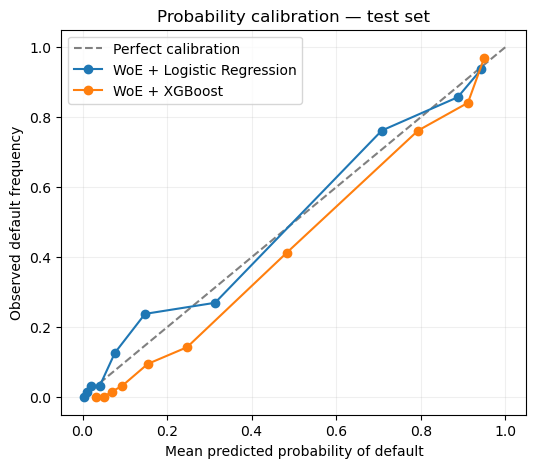

,Brier score,Brier skill vs training base rate,Mean predicted PD,Observed default rate
Model,,,,
WoE + Logistic Regression,0.0906,0.5880,0.3146,0.3265
WoE + XGBoost,0.0835,0.6201,0.3779,0.3265


In [26]:
base_rate = float(y_train.mean())
reference_brier = brier_score_loss(y_test, np.full(len(y_test), base_rate))

plt.figure(figsize=(6, 5))
plt.plot([0, 1], [0, 1], "--", color="grey", label="Perfect calibration")
calibration_rows = []
for name, probabilities in test_proba.items():
    observed, predicted = calibration_curve(y_test, probabilities, n_bins=10, strategy="quantile")
    plt.plot(predicted, observed, marker="o", label=name)
    brier = brier_score_loss(y_test, probabilities)
    calibration_rows.append({
        "Model": name, "Brier score": brier,
        "Brier skill vs training base rate": 1 - brier / reference_brier if reference_brier > 0 else np.nan,
        "Mean predicted PD": probabilities.mean(),
        "Observed default rate": y_test.mean()
    })
plt.xlabel("Mean predicted probability of default")
plt.ylabel("Observed default frequency")
plt.title("Probability calibration — test set")
plt.legend()
plt.grid(alpha=0.2)
plt.show()
display(pd.DataFrame(calibration_rows).set_index("Model").round(4))

### 5.6 Population Stability Index (PSI)

PSI compares the distribution of predicted PDs in the training and test populations. It is a population-shift indicator, not a measure of predictive accuracy. The commonly used guide is: PSI below 0.10 = little change; 0.10–0.25 = moderate change; above 0.25 = substantial change. These are practical flags, not universal regulatory thresholds.

In [27]:
def calculate_psi(reference, current, bins=10):
    reference = np.asarray(reference, dtype=float)
    current = np.asarray(current, dtype=float)
    quantile_edges = np.unique(np.quantile(reference, np.linspace(0, 1, bins + 1)))
    if len(quantile_edges) < 3:
        quantile_edges = np.linspace(min(reference.min(), current.min()) - 1e-8,
                                     max(reference.max(), current.max()) + 1e-8, bins + 1)
    else:
        quantile_edges[0], quantile_edges[-1] = -np.inf, np.inf
    ref_counts = np.histogram(reference, bins=quantile_edges)[0]
    cur_counts = np.histogram(current, bins=quantile_edges)[0]
    ref_pct = np.clip(ref_counts / max(ref_counts.sum(), 1), 1e-6, None)
    cur_pct = np.clip(cur_counts / max(cur_counts.sum(), 1), 1e-6, None)
    return float(np.sum((cur_pct - ref_pct) * np.log(cur_pct / ref_pct)))

psi_rows = []
for name in models:
    psi = calculate_psi(train_proba[name], test_proba[name])
    psi_rows.append({
        "Model": name, "PD distribution PSI": psi,
        "Stability flag": "Stable (<0.10)" if psi < 0.10 else
                          "Moderate shift (0.10–0.25)" if psi < 0.25 else "Material shift (>0.25)"
    })
psi_df = pd.DataFrame(psi_rows).set_index("Model")
display(psi_df.round(4))

,PD distribution PSI,Stability flag
Model,,
WoE + Logistic Regression,0.0086,Stable (<0.10)
WoE + XGBoost,0.0077,Stable (<0.10)


### 5.7 Stability across borrower segments

Compare test-set AUC and KS for real-estate exposure, recession status, and loan-size groups. A segment with too few loans or only one target class is not assigned an AUC. Loan-size cut points are learned from the training set only.

In [28]:
MIN_SEGMENT = 30
size_edges = np.unique(np.quantile(X_train["DisbursementGross"], [0.25, 0.50, 0.75]))
size_labels = ["Smallest loans", "Lower-middle loans", "Upper-middle loans", "Largest loans"]
size_group = np.digitize(X_test["DisbursementGross"], size_edges)

segment_labels = {
    "Real estate": np.where(X_test["RealEstate"].to_numpy() == 1, "Real-estate backed", "Not real-estate backed"),
    "Recession": np.where(X_test["Recession"].to_numpy() == 1, "During recession", "Outside recession"),
    "Loan size": np.asarray(size_labels)[size_group]
}
segment_rows = []
for name, probabilities in test_proba.items():
    overall_auc = roc_auc_score(y_test, probabilities)
    for segment_name, labels in segment_labels.items():
        for group in pd.unique(labels):
            mask = labels == group
            y_segment = y_test.to_numpy()[mask]
            p_segment = probabilities[mask]
            if mask.sum() < MIN_SEGMENT or np.unique(y_segment).size < 2:
                continue
            auc = roc_auc_score(y_segment, p_segment)
            segment_rows.append({
                "Model": name, "Segment": segment_name, "Group": group,
                "Loans": int(mask.sum()), "Default rate": y_segment.mean(),
                "AUC": auc, "KS": ks_statistic(y_segment, p_segment),
                "AUC drop vs overall": overall_auc - auc,
                "Flag": "Review" if overall_auc - auc > GAP_LIMIT else "No large drop"
            })
segment_df = pd.DataFrame(segment_rows)
if not segment_df.empty:
    display(segment_df.set_index(["Model", "Segment", "Group"]).round(4))
else:
    print("No segments met the minimum sample-size and two-class requirements.")

Loans  \
Model                     Segment     Group                           
WoE + Logistic Regression Real estate Real-estate backed        175   
                                      Not real-estate backed    456   
                          Recession   Outside recession         589   
                                      During recession           42   
                          Loan size   Largest loans             159   
                                      Upper-middle loans        160   
                                      Smallest loans            166   
                                      Lower-middle loans        146   
WoE + XGBoost             Real estate Real-estate backed        175   
                                      Not real-estate backed    456   
                          Recession   Outside recession         589   
                                      During recession           42   
                          Loan size   Largest loans             159   
                                      Upper-middle loans        160   
                                      Smallest loans            166   
                                      Lower-middle loans        146   

                                                              Default rate  \
Model                     Segment     Group                                  
WoE + Logistic Regression Real estate Real-estate backed            0.0514   
                                      Not real-estate backed        0.4320   
                          Recession   Outside recession             0.3124   
                                      During recession              0.5238   
                          Loan size   Largest loans                 0.1006   
                                      Upper-middle loans            0.2688   
                                      Smallest loans                0.4518   
                                      Lower-middle loans            0.4932   
WoE + XGBoost             Real estate Real-estate backed            0.0514   
                                      Not real-estate backed        0.4320   
                          Recession   Outside recession             0.3124   
                                      During recession              0.5238   
                          Loan size   Largest loans                 0.1006   
                                      Upper-middle loans            0.2688   
                                      Smallest loans                0.4518   
                                      Lower-middle loans            0.4932   

                                                                 AUC      KS  \
Model                     Segment     Group                                    
WoE + Logistic Regression Real estate Real-estate backed      0.8963  0.7564   
                                      Not real-estate backed  0.9141  0.7471   
                          Recession   Outside recession       0.9312  0.7540   
                                      During recession        0.8932  0.7136   
                          Loan size   Largest loans           0.8378  0.6377   
                                      Upper-middle loans      0.9342  0.7750   
                                      Smallest loans          0.9282  0.7811   
                                      Lower-middle loans      0.9375  0.8086   
WoE + XGBoost             Real estate Real-estate backed      0.9866  0.9699   
                                      Not real-estate backed  0.9271  0.7573   
                          Recession   Outside recession       0.9533  0.7985   
                                      During recession        0.8977  0.6727   
                          Loan size   Largest loans           0.9187  0.7692   
                                      Upper-middle loans      0.9569  0.8471   
                                      Smallest loans          0.9255  0.7575   
                  

### 5.8 WoE/IV screening and model feature importance

The following IV table is fitted on the training data only. Variables with IV above 0.50 must be investigated for leakage or unusually strong proxies before being accepted. The final feature selection inside each cross-validation fold is still performed by the pipeline transformer.

In [29]:
if WOE_CANDIDATES:
    iv_inspector = WoEIVTransformer(n_bins=5, min_count=20, iv_threshold=IV_THRESHOLD)
    iv_inspector.fit(X_train[WOE_CANDIDATES], y_train)
    display(iv_inspector.iv_table_.round(4))
    suspicious = iv_inspector.iv_table_.query("IV > 0.50")
    if len(suspicious):
        print("Investigate these high-IV variables for leakage before use:")
        display(suspicious)
    else:
        print("No candidate variable has IV > 0.50 in this training sample.")
else:
    print("No additional WoE candidate columns are available in this dataset.")

,IV,Interpretation
Term,1.8339,Investigate: IV > 0.50
SBA_Appv,1.0183,Investigate: IV > 0.50
GrAppv,0.9941,Investigate: IV > 0.50
ApprovalFY,0.9877,Investigate: IV > 0.50
RevLineCr,0.7218,Investigate: IV > 0.50
NAICS4,0.4325,Strong
UrbanRural,0.2658,Medium
NoEmp,0.2228,Medium
LoanPerEmployee,0.1843,Medium
RetainedJob,0.1672,Medium


Investigate these high-IV variables for leakage before use:


,IV,Interpretation
Term,1.833919,Investigate: IV > 0.50
SBA_Appv,1.018281,Investigate: IV > 0.50
GrAppv,0.994118,Investigate: IV > 0.50
ApprovalFY,0.987733,Investigate: IV > 0.50
RevLineCr,0.721805,Investigate: IV > 0.50


### 5.9 Feature importance and interpretability

For Logistic Regression, inspect coefficient direction and magnitude after WoE transformation. For XGBoost, inspect gain-based feature importance. These explain model behavior; they do not establish causality.

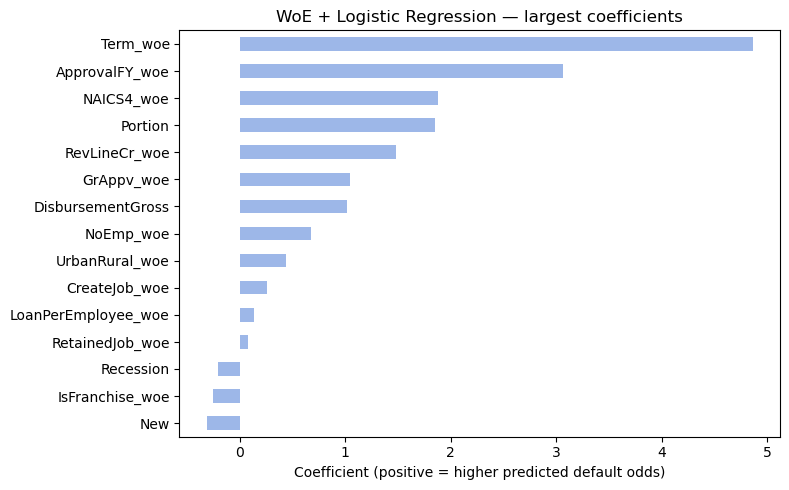

,Coefficient
SBA_Appv_woe,-1.499981
RealEstate,-1.086117
New,-0.310096
IsFranchise_woe,-0.253779
Recession,-0.202920
RetainedJob_woe,0.079744
LoanPerEmployee_woe,0.141213
CreateJob_woe,0.263280
UrbanRural_woe,0.443408
NoEmp_woe,0.672515


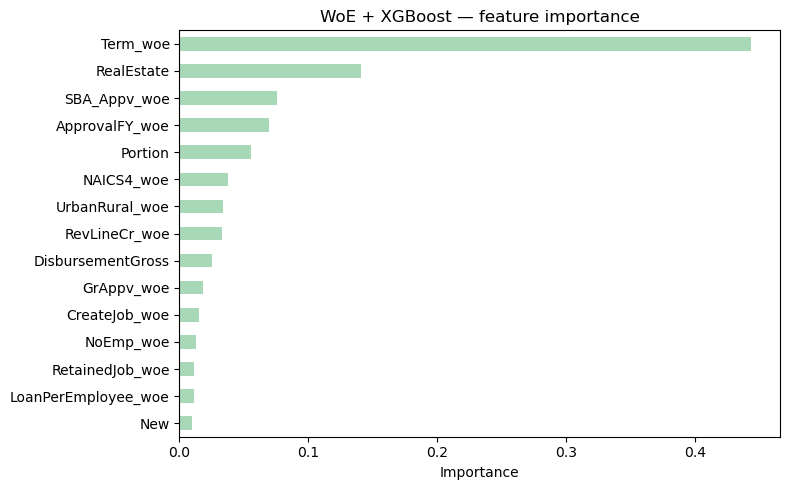

,Importance
Term_woe,0.443722
RealEstate,0.141148
SBA_Appv_woe,0.075400
ApprovalFY_woe,0.069801
Portion,0.055396
NAICS4_woe,0.037417
UrbanRural_woe,0.033599
RevLineCr_woe,0.032746
DisbursementGross,0.025019
GrAppv_woe,0.017998


In [30]:
for name, model in models.items():
    preprocessor = model.named_steps["columntransformer"]
    feature_names = preprocessor.get_feature_names_out()

    if name == "WoE + Logistic Regression":
        estimator = model.named_steps["logisticregression"]
        importance = pd.Series(estimator.coef_[0], index=feature_names).sort_values()
        ax = importance.tail(15).plot(kind="barh", figsize=(8, 5), color="#9db7e8")
        ax.set_title("WoE + Logistic Regression — largest coefficients")
        ax.set_xlabel("Coefficient (positive = higher predicted default odds)")
        plt.tight_layout()
        plt.show()
        display(importance.to_frame("Coefficient"))
    else:
        estimator = model.named_steps["xgbclassifier"]
        importance = pd.Series(estimator.feature_importances_, index=feature_names).sort_values(ascending=False)
        ax = importance.head(15).sort_values().plot(kind="barh", figsize=(8, 5), color="#a9d8b8")
        ax.set_title("WoE + XGBoost — feature importance")
        ax.set_xlabel("Importance")
        plt.tight_layout()
        plt.show()
        display(importance.to_frame("Importance"))

### 5.10 Hyperparameter search diagnostics

Review the best cross-validation score and the spread of the top parameter configurations. A high training-CV score is not proof of future performance. Compare it with the untouched test AUC and the temporal validation results. Do not repeatedly change the model based on the test set.

In [31]:
for name, search in searches.items():
    cv_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
    cols = ["mean_test_score", "std_test_score", "mean_train_score", "std_train_score", "params"]
    print(f"\\n{name}: top 5 parameter configurations")
    display(cv_results[cols].head(5).reset_index(drop=True))


\nWoE + Logistic Regression: top 5 parameter configurations


,mean_test_score,std_test_score,mean_train_score,std_train_score,params
0,0.934170,0.010523,0.944749,0.005551,"{'logisticregression__class_weight': None, 'lo..."
1,0.932810,0.011357,0.942891,0.005542,{'logisticregression__class_weight': 'balanced...
2,0.927086,0.007970,0.937306,0.002980,"{'logisticregression__class_weight': None, 'lo..."
3,0.925976,0.009170,0.931820,0.002614,{'logisticregression__class_weight': 'balanced...
4,0.925503,0.009636,0.931921,0.002635,{'logisticregression__class_weight': 'balanced...


\nWoE + XGBoost: top 5 parameter configurations


,mean_test_score,std_test_score,mean_train_score,std_train_score,params
0,0.956415,0.005877,0.969623,0.002733,"{'xgbclassifier__subsample': 1.0, 'xgbclassifi..."
1,0.956137,0.008179,0.979801,0.001554,"{'xgbclassifier__subsample': 0.95, 'xgbclassif..."
2,0.952298,0.007387,0.976493,0.001721,"{'xgbclassifier__subsample': 0.65, 'xgbclassif..."
3,0.951413,0.005876,0.966811,0.001978,"{'xgbclassifier__subsample': 0.95, 'xgbclassif..."
4,0.950444,0.006969,0.965282,0.002805,"{'xgbclassifier__subsample': 0.65, 'xgbclassif..."


### 5.11 PDO score scaling (WoE Logistic Regression)

For a scorecard-style presentation, convert the Logistic Regression PD into a points score. This is a rescaling of the estimated probability, not a new model. The example uses a base score of 600, base odds of 50:1 (non-default to default), and PDO = 20. Higher scores indicate lower default risk. Change the reference values if your project uses a different scorecard convention.

In [32]:
BASE_SCORE = 600
BASE_ODDS_GOOD_TO_BAD = 50
PDO = 20
FACTOR = PDO / np.log(2)
OFFSET = BASE_SCORE - FACTOR * np.log(BASE_ODDS_GOOD_TO_BAD)

logit_pd = np.clip(test_proba["WoE + Logistic Regression"], 1e-8, 1 - 1e-8)
good_to_bad_odds = (1 - logit_pd) / logit_pd
credit_scores = OFFSET + FACTOR * np.log(good_to_bad_odds)

scorecard_results = pd.DataFrame({
    "Predicted PD": logit_pd,
    "Good-to-bad odds": good_to_bad_odds,
    "PDO score": credit_scores
}, index=y_test.index)
display(scorecard_results.head(10).round(2))
print(f"PDO={PDO}, Factor={FACTOR:.2f}, Offset={OFFSET:.2f}")

,Predicted PD,Good-to-bad odds,PDO score
1264,0.01,101.22,620.35
1962,0.87,0.15,432.08
2055,0.90,0.11,424.08
596,0.92,0.09,416.28
2049,0.02,40.10,593.63
620,0.93,0.07,410.70
338,0.00,511.75,667.11
21,0.04,21.82,576.07
1321,0.31,2.24,510.40
479,0.13,6.91,542.90


PDO=20, Factor=28.85, Offset=487.12


## 6. Scenario-based decision

Apply the two WoE models to the two example California loan applications. The five case-study variables are entered explicitly. Additional WoE candidate variables are assigned transparent typical-value assumptions from the training set because the case description does not provide those details. Replace these assumptions if borrower-level information becomes available.

In [33]:
loans = pd.DataFrame({
    "Loan": [1, 2],
    "Name": ["Carmichael Realty", "SV Consulting"],
    "Loan amount requested": [1_000_000, 100_000],
    "SBA portion guaranteed ($)": [750_000, 40_000],
    "Secured by real estate?": ["Yes", "No"]
})

scenario_X = pd.DataFrame({
    "Recession": [0, 0],
    "New": [0, 0],  # Assumption: established businesses; confirm with case information
    "RealEstate": [1, 0],
    "DisbursementGross": loans["Loan amount requested"],
    "Portion": loans["SBA portion guaranteed ($)"] / loans["Loan amount requested"]
})

# Fill additional WoE candidates with typical training values only where the case lacks information.
for col in WOE_CANDIDATES:
    if pd.api.types.is_numeric_dtype(X_train[col]):
        scenario_X[col] = X_train[col].median()
    else:
        modes = X_train[col].mode(dropna=True)
        scenario_X[col] = modes.iloc[0] if len(modes) else "__MISSING__"

scenario_X = scenario_X[MODEL_INPUTS]
display(scenario_X)

,Recession,New,RealEstate,DisbursementGross,Portion,NoEmp,NAICS4,UrbanRural,LowDoc,RevLineCr,IsFranchise,Term,SBA_Appv,GrAppv,CreateJob,RetainedJob,ApprovalFY,LoanPerEmployee
0,0,0,1,1000000,0.75,4.0,5312,1,N,Y,0.0,84.0,41760.0,63000.0,0.0,2.0,2005.0,25000.0
1,0,0,0,100000,0.40,4.0,5312,1,N,Y,0.0,84.0,41760.0,63000.0,0.0,2.0,2005.0,25000.0


In [34]:
scenario_results = pd.DataFrame({"Loan": loans["Name"]})
for name, model in models.items():
    scenario_results[name + " — PD"] = model.predict_proba(scenario_X)[:, 1]
    scenario_results[name + " — Decision"] = np.where(
        scenario_results[name + " — PD"] <= CUTOFF, "Lower risk / approve", "Higher risk / review or deny"
    )
display(scenario_results.round(4))
print("Decision cutoff:", CUTOFF)
print("Important: these are model-based scenario outputs, not lending recommendations. Review assumptions and bank policy before any real decision.")

,Loan,WoE + Logistic Regression — PD,WoE + Logistic Regression — Decision,WoE + XGBoost — PD,WoE + XGBoost — Decision
0,Carmichael Realty,0.089,Lower risk / approve,0.1876,Lower risk / approve
1,SV Consulting,0.062,Lower risk / approve,0.1421,Lower risk / approve


Decision cutoff: 0.5
Important: these are model-based scenario outputs, not lending recommendations. Review assumptions and bank policy before any real decision.


## 7. Conclusion and limitations

Use the evaluation and validation tables together rather than selecting a model from AUC alone. Consider discrimination (AUC, Gini, KS), classification errors (confusion matrix, precision and recall), probability quality (Brier score, log loss and calibration), generalization (overfitting and cross-validation), and population/segment stability (PSI and segment-level AUC).

The case study remains limited to approved SBA loans, California, NAICS sector 53, and the historical observation period. It does not contain applicant credit scores and therefore cannot represent the full population of businesses that applied for credit. Model outputs should be interpreted within these limitations.